First, I import pandas so I can load and work with the tables in this notebook.

In [4]:
import pandas as pd

The raw event file is too large to load all at once, so I read it in chunks of 500,000 rows. I keep about 1 in every 200 users by hashing the user ID, then add each chunk to the output CSV. The hash keeps the same users in the sample each time, and writing the header only for the first chunk prevents repeated column names in the file.

In [5]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path("/home/manish-singh/Codes (Linux)/MACHINE LEARNING/ASSIGNMENT/Memory Lab: spaced-repetition-scheduler")
tsv_file = BASE_DIR / "data/raw/opensource_dataset.tsv"
out_csv = BASE_DIR / "data/processed/maimemo_sample.csv"

first_chunk = True
for chunk in pd.read_table(tsv_file, sep="\t", chunksize=500_000):
    user_hash = pd.util.hash_pandas_object(chunk["u"], index=False)
    sampled = chunk[(user_hash % 200) == 0]
    
    sampled.to_csv(out_csv, mode="w" if first_chunk else "a", header=first_chunk, index=False)
    first_chunk = False

print(f"Done! Saved -> {out_csv}")

Done! Saved -> /home/manish-singh/Codes (Linux)/MACHINE LEARNING/ASSIGNMENT/Memory Lab: spaced-repetition-scheduler/data/processed/maimemo_sample.csv


Now I load the sample and take a look at what is in it: its size, columns, data types, missing values, a few example rows, and some summary statistics. I also check how often each response value appears, which gives me a quick sense of the label balance.

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path
BASE_DIR = BASE_DIR = Path("/home/manish-singh/Codes (Linux)/MACHINE LEARNING/ASSIGNMENT/Memory Lab: spaced-repetition-scheduler")
df = pd.read_csv(BASE_DIR / "data/processed/maimemo_sample.csv")

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Unique Users (u): {df['u'].nunique():,} | Unique Words (w): {df['w'].nunique():,}\n")
print(df.info())
print(df.isnull().sum())

display(df.head(10))
display(df.describe())

print(df["r"].value_counts(dropna=False))
print((df["r"].value_counts(normalize=True) * 100).round(2))

Shape: 1,081,771 rows x 7 columns
Unique Users (u): 4,131 | Unique Words (w): 20,154

<class 'pandas.DataFrame'>
RangeIndex: 1081771 entries, 0 to 1081770
Data columns (total 7 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   u          1081771 non-null  str  
 1   w          1081762 non-null  str  
 2   i          1081771 non-null  int64
 3   t_history  1081771 non-null  str  
 4   r_history  1081771 non-null  str  
 5   delta_t    1081771 non-null  int64
 6   r          1081771 non-null  int64
dtypes: int64(3), str(4)
memory usage: 96.3 MB
None
u            0
w            9
i            0
t_history    0
r_history    0
delta_t      0
r            0
dtype: int64


,u,w,i,t_history,r_history,delta_t,r
0,aa676f,pessimistic,9,"0,1,3,5,7,15,30,60","0,1,1,1,1,1,1,1",75,1
1,aa676f,volatile,16,"0,1,2,5,9,1,4,8,1,3,1,1,1,1,3","0,1,1,1,0,1,1,0,1,0,0,0,0,1,0",1,1
2,aa676f,draft,8,"0,1,2,6,1,4,7","0,1,1,0,1,1,0",1,1
3,aa676f,lump,6,"0,1,2,6,12","0,1,1,1,0",1,1
4,aa676f,frontier,6,"0,1,2,6,12","0,1,1,1,0",1,1
5,aa676f,territory,13,"0,1,2,5,1,4,6,9,11,30,1,3","0,1,1,0,1,1,1,1,1,0,1,1",5,1
6,aa676f,deter,18,"0,1,3,1,3,5,1,4,6,7,1,3,5,7,15,30,1","0,1,0,1,1,0,1,1,1,0,1,1,1,1,1,0,1",3,1
7,aa676f,sheet,12,"0,1,2,6,12,1,5,8,12,1,3","0,1,1,1,0,1,1,1,0,1,1",5,1
8,aa676f,sniff,14,"0,1,3,6,12,18,2,6,11,11,15,1,3","0,1,1,1,1,0,1,1,1,1,0,1,1",5,1
9,aa676f,judicial,15,"0,1,3,5,7,15,30,60,1,3,5,7,15,30","0,1,1,1,1,1,1,0,1,1,1,1,1,1",60,1


,i,delta_t,r
count,1.081771e+06,1.081771e+06,1.081771e+06
mean,7.421511e+00,8.744902e+00,7.585663e-01
std,6.454793e+00,1.539286e+01,4.279529e-01
min,2.000000e+00,1.000000e+00,0.000000e+00
25%,3.000000e+00,1.000000e+00,1.000000e+00
50%,5.000000e+00,3.000000e+00,1.000000e+00
75%,9.000000e+00,7.000000e+00,1.000000e+00
max,8.700000e+01,1.040000e+02,1.000000e+00


r
1    820595
0    261176
Name: count, dtype: int64
r
1    75.86
0    24.14
Name: proportion, dtype: float64


Before cleaning the data, I check the missing-value counts once more so I can see which columns still have gaps.

In [7]:
print(df.isnull().sum())

u            0
w            9
i            0
t_history    0
r_history    0
delta_t      0
r            0
dtype: int64


I remove rows with missing values, blank word or history fields, and exact duplicates. Then I check the missing-value counts again to make sure the remaining rows are complete.

In [8]:
df = df.dropna().copy()
df = df[
    (df["w"].astype(str).str.strip() != "") &
    (df["t_history"].astype(str).str.strip() != "") &
    (df["r_history"].astype(str).str.strip() != "")
].drop_duplicates()

print(df.isnull().sum())

u            0
w            0
i            0
t_history    0
r_history    0
delta_t      0
r            0
dtype: int64


Next I check the saved model on the same unseen-user holdout used during training. I rebuild the split by student ID, then compare its predictions with the actual recall outcomes using ranking, probability-error, and accuracy metrics. This gives us a real test of the trained model rather than just checking that the file loads.

In [9]:
import joblib
import polars as pl
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, accuracy_score

model_bundle = joblib.load(BASE_DIR / "models/syllabus_gb_model.joblib")
feature_cols = model_bundle["features"]
holdout_data = pl.read_parquet(BASE_DIR / "data/processed/features_1m.parquet")
X = holdout_data.select(feature_cols).to_numpy()
y = holdout_data["r"].to_numpy()
students = holdout_data["u"].to_numpy()

# Use the same grouped split settings as src/train.py and src/evaluate.py.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
_, test_idx = next(splitter.split(X, y, groups=students))
X_test, y_test = X[test_idx], y[test_idx]
y_prob = model_bundle["model"].predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

holdout_metrics = pd.DataFrame({
    "Metric": ["ROC-AUC", "Log loss", "Brier score", "Accuracy"],
    "Score": [
        roc_auc_score(y_test, y_prob),
        log_loss(y_test, y_prob),
        brier_score_loss(y_test, y_prob),
        accuracy_score(y_test, y_pred),
    ],
})
print(f"Unseen-user test rows: {len(y_test):,}")
display(holdout_metrics.round(4))


Unseen-user test rows: 228,537


,Metric,Score
0,ROC-AUC,0.7076
1,Log loss,0.4971
2,Brier score,0.1623
3,Accuracy,0.7676


These plots help make the holdout results easier to interpret. The calibration plot checks whether predicted probabilities match observed recall rates, while the confusion matrix shows the correct and incorrect predictions at the 0.5 cutoff. A well-calibrated model should track the diagonal in the first plot.

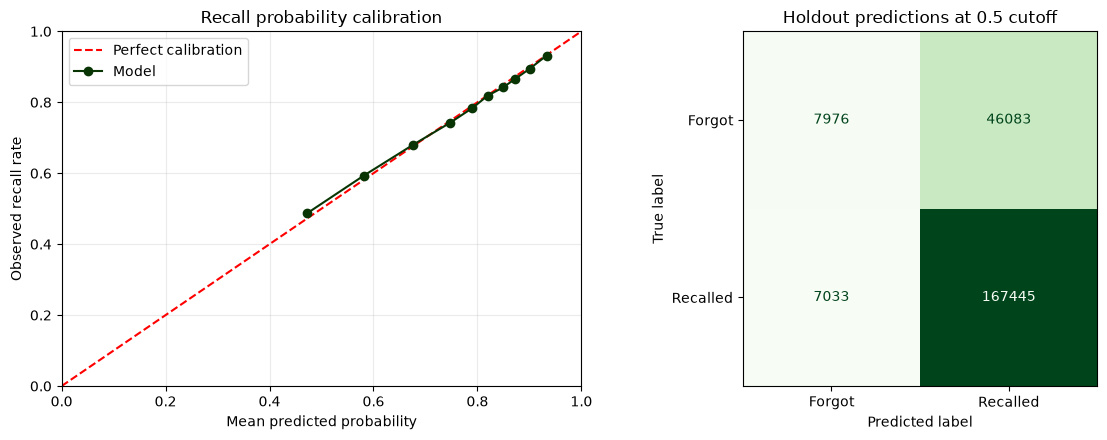

In [10]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay

observed_rate, mean_probability = calibration_curve(
    y_test, y_prob, n_bins=10, strategy="quantile"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot([0, 1], [0, 1], "--", color="red", label="Perfect calibration")
axes[0].plot(mean_probability, observed_rate, "o-", color="#093504", label="Model")
axes[0].set(title="Recall probability calibration", xlabel="Mean predicted probability", ylabel="Observed recall rate", xlim=(0, 1), ylim=(0, 1))
axes[0].grid(alpha=0.25)
axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Forgot", "Recalled"],
    cmap="Greens", colorbar=False, ax=axes[1]
)
axes[1].set_title("Holdout predictions at 0.5 cutoff")
fig.tight_layout()
plt.show()
